In [1]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENROUTER_API_KEY"]=os.getenv("OPENROUTER_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [2]:
from deepagents import create_deep_agent
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1"
)

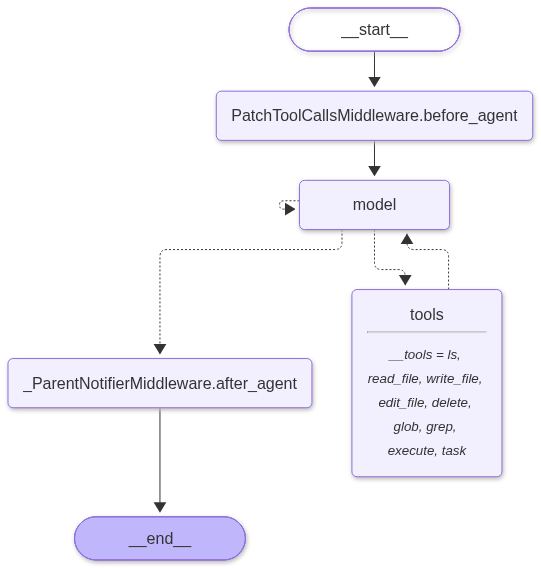

In [5]:
import os
from typing import Literal

from deepagents import create_deep_agent
from tavily import TavilyClient

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,

):
 """Run a web search"""
 return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )


research_subagent={
    "name": "research-agent",
    "description": "Used to research more in depth questions",
    "system_prompt": "You are a great researcher",
    "tools": [internet_search],
    "model":model,  # Optional override, defaults to main agent model

}
subagents=[research_subagent]

agent=create_deep_agent(
    model=model,
    subagents=subagents
)
agent


In [6]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "Reserach about LLM Gateways and provide me a detailed summary.",       
          }],
          
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Reserach about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================
Tool Calls:
  task (call-51a07f55-0f46-4cfc-9803-e06e57883ea9)
 Call ID: call-51a07f55-0f46-4cfc-9803-e06e57883ea9
  Args:
    subagent_type: research-agent
    description: Research LLM Gateways (also known as AI Gateways, LLM Proxies, or Model Gateways) and provide a comprehensive summary covering:

1. What is an LLM Gateway - definition and core purpose
2. Key features and capabilities (routing, load balancing, caching, observability, security, cost management, etc.)
3. Major open-source and commercial solutions (e.g., Portkey, LiteLLM, Kong AI Gateway, MLflow AI Gateway, Cloudflare AI Gateway, etc.)
4. Architecture patterns and how they integrate with existing infrastructure
5. Use cases and benefits for organizations
6. Challenges and considerations when adop

## Structured Output with Subagents

In [7]:
from pydantic import BaseModel, Field
from deepagents import create_deep_agent

class ResearchFindings(BaseModel):
    """Structured findings from a research task."""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="Confidence score from 0 to 1")
    sources: list[str] = Field(description="List of source URLs")

research_subagent = {
    "name": "researcher",
    "description": "Researches topics and returns structured findings",
    "system_prompt": "Research the given topic thoroughly. Return your findings.",
    "tools": [internet_search],
    "response_format": ResearchFindings,
}

agent = create_deep_agent(
    model=model,
    subagents=[research_subagent],
)

result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "Research recent ai news"}]}
)

In [8]:
# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Research recent ai news
================================== Ai Message ==================================
Tool Calls:
  task (call-d3e59a1f-d666-41ac-b290-b03ef58ce810)
 Call ID: call-d3e59a1f-d666-41ac-b290-b03ef58ce810
  Args:
    description: Research recent AI news from the past few weeks. Focus on:
1. Major AI model releases/updates (GPT, Claude, Gemini, Llama, etc.)
2. Significant AI company news (OpenAI, Anthropic, Google, Meta, etc.)
3. Important research papers or breakthroughs
4. AI regulation/policy developments
5. Major funding rounds or acquisitions
6. Notable AI applications or deployments

Return a structured summary organized by category with dates and sources where possible.
    subagent_type: researcher
================================= Tool Message =================================
Name: task

{"summary":"## Recent AI News Summary (October-November 2024 Focus) from a US/North American pe